# CivicFix AI — Assignment 1: Exploratory Data Analysis
**Group 8** · Tunahan Onur Direk · Yağmur Sert · Sezin Naz Sarı

Goal: understand citizen infrastructure complaints (roads, sidewalks, sewers/drainage),
how they relate to rainfall, how fast they are resolved, and whether they cluster in
recurring hotspots — the signals CivicFix AI will use to prioritise municipal work.

Data
NYC 311 Service Requests (NYC Open Data, `erm2-nwe9`) — all 2025 complaints of type
   Street Condition, Sidewalk Condition, Sewer, Root/Sewer/Sidewalk Condition (132,653 rows).
   Used because it is the largest open, record-level, labelled municipal complaint log.
Weather feature: NOAA GHCN-Daily, Central Park station USW00094728 — daily precipitation 2025, joined by date.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib as mpl
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, classification_report
import os, json
from matplotlib.patches import Patch
mpl.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True, 'grid.color': '#e8e7e3',
    'grid.linewidth': 0.6, 'axes.axisbelow': True, 'figure.dpi': 160, 'axes.titlesize': 10,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#9b9a95'
TIER_COL = {'Critical': '#e34948', 'High': '#eb6834', 'Routine': '#9b9a95'}
STATS = {}

## 1. Load & clean

In [2]:
df = pd.read_csv('nyc311_infra_2025.csv', low_memory=False, parse_dates=['created_date', 'closed_date'])
STATS['rows_raw'] = len(df)
df = df.drop_duplicates('unique_key')
df = df[df.borough != 'Unspecified']
# Resolution time in days; drop negative / impossible closures
df['res_days'] = (df.closed_date - df.created_date).dt.total_seconds() / 86400
bad = df.res_days < 0
STATS['negative_res'] = int(bad.sum())
df.loc[bad, 'res_days'] = np.nan
# Clean descriptor text: drop agency codes like "(SC)"
df['issue'] = df.descriptor.str.replace(r'\s*\((Use Comments|Emergency)\)', '', regex=True).str.replace(r'\s*\([A-Z0-9]+\)$', '', regex=True).str.strip()
df['month'] = df.created_date.dt.month
df['dow'] = df.created_date.dt.dayofweek
df['date'] = df.created_date.dt.normalize()
STATS['rows_clean'] = len(df)
missing = df[['closed_date', 'latitude', 'location_type', 'incident_zip', 'resolution_description']].isna().mean().mul(100).round(1)
print(missing)
STATS['missing_pct'] = missing.to_dict()

closed_date                5.6
latitude                  15.0
location_type             48.8
incident_zip               0.5
resolution_description     2.6
dtype: float64


## 2. Hazard taxonomy (the priority label CivicFix will predict)
Each issue is mapped to a hazard tier using public-safety logic: *Critical* = immediate
risk of injury, vehicle loss or flooding of property; *High* = damage that worsens fast or
blocks accessibility; *Routine* = nuisance / administrative. Flood-related issues are flagged separately.

In [3]:
CRITICAL = ['Cave-in', 'Sidewalk Collapsed', 'Manhole Cover Missing', 'Catch Basin Grating Missing',
    'Plate Condition - Open', 'Street Flooding', 'Highway Flooding', 'Manhole Overflow', 'Sewer Backup',
    'Cellar Door Open/Unprotected', 'Guard Rail - Street', 'Crash Cushion Defect', 'Unsafe Worksite',
    'Sidewalk Grating - Missing', 'Metal Protruding - Sign Stump']
HIGH = ['Pothole', 'Catch Basin Clogged/Flooding', 'Broken Sidewalk', 'Failed Street Repair',
    'Plate Condition - Shifted', 'Catch Basin Sunken/Damaged/Raised', 'Pedestrian Ramp Defective',
    'Culvert Blocked/Needs Cleaning', 'Defective Hardware', 'Rough, Pitted or Cracked Roads',
    'Sidewalk Grating - Defective', 'Sidewalk Staircase', 'Defective/Missing Curb Piece',
    'Affecting Sewer or Foundation', 'Depression Maintenance', 'Hummock', 'Cellar Door Defective']
FLOOD = ['Sewer Backup', 'Catch Basin Clogged/Flooding', 'Street Flooding', 'Manhole Overflow',
    'Highway Flooding', 'Culvert Blocked/Needs Cleaning']
df['tier'] = np.select([df.issue.isin(CRITICAL), df.issue.isin(HIGH)], ['Critical', 'High'], 'Routine')
df['flood'] = df.issue.isin(FLOOD)
print(df.tier.value_counts(normalize=True).round(3))
STATS['tier_share'] = df.tier.value_counts(normalize=True).round(3).to_dict()
STATS['n_issue_types'] = df.issue.nunique()

tier
High        0.537
Routine     0.275
Critical    0.188
Name: proportion, dtype: float64


## 3. Descriptive statistics

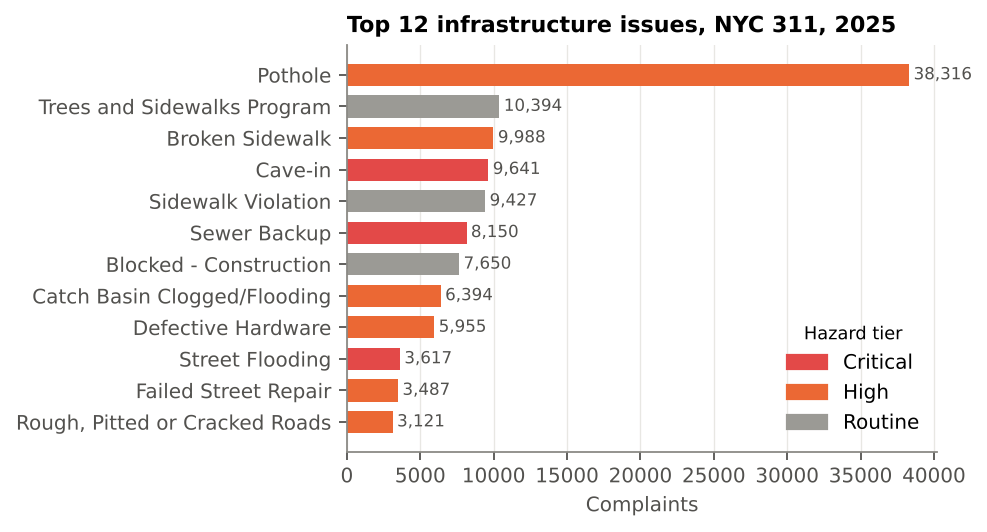

In [4]:
top = df.issue.value_counts().head(12)[::-1]
tier_of = df.drop_duplicates('issue').set_index('issue').tier
fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.barh(top.index, top.values, color=[TIER_COL[tier_of[i]] for i in top.index], height=0.7)
for y, v in enumerate(top.values):
    ax.text(v + 300, y, f'{v:,}', va='center', fontsize=7.5, color='#52514e')
ax.set_title('Top 12 infrastructure issues, NYC 311, 2025')
ax.set_xlabel('Complaints'); ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color=c, label=t) for t, c in TIER_COL.items()], frameon=False, loc='lower right', title='Hazard tier', title_fontsize=8)
fig.tight_layout(); fig.savefig('fig1_top_issues.png'); plt.show()
STATS['top_issues'] = df.issue.value_counts().head(5).to_dict()

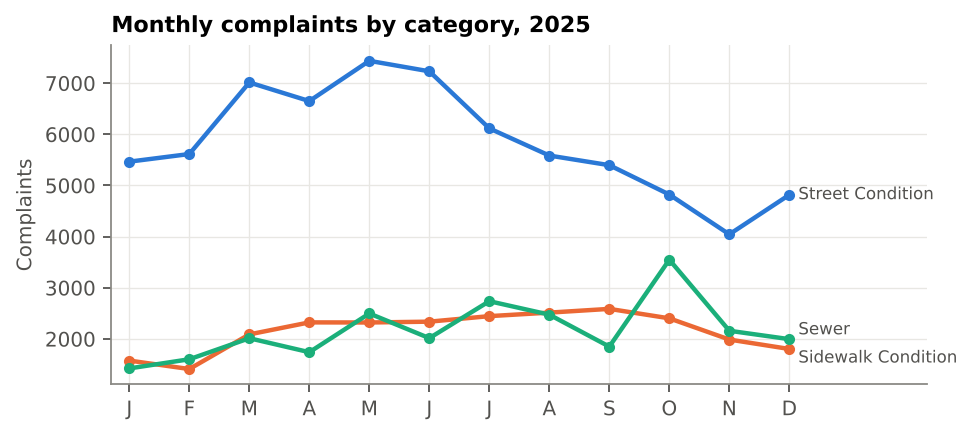

In [5]:
by_type = df.groupby(['month', 'complaint_type']).size().unstack(fill_value=0)
by_type = by_type[['Street Condition', 'Sidewalk Condition', 'Sewer']]
fig, ax = plt.subplots(figsize=(6.2, 2.8))
for col, c in zip(by_type.columns, [BLUE, ORANGE, AQUA]):
    ax.plot(by_type.index, by_type[col], color=c, lw=2, marker='o', ms=4)
    ax.text(12.15, by_type[col].iloc[-1] + {'Sewer': 180, 'Sidewalk Condition': -180}.get(col, 0), col, color='#52514e', fontsize=7.5, va='center')
ax.set_xticks(range(1, 13)); ax.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'])
ax.set_xlim(0.7, 14.3); ax.set_title('Monthly complaints by category, 2025'); ax.set_ylabel('Complaints')
fig.tight_layout(); fig.savefig('fig2_monthly.png'); plt.show()
STATS['pothole_by_month'] = df[df.issue == 'Pothole'].groupby('month').size().to_dict()

## 4. Rainfall ↔ flood complaints

                mean  size
rain_bin                  
Dry (0)    41.786885   244
0–5 mm     46.485294    68
5–20 mm    84.200000    40
>20 mm    237.230769    13
          date  flood  rain_mm
302 2025-10-30   1650     46.5
211 2025-07-31    500      8.1
303 2025-10-31    312      0.0
352 2025-12-19    299     29.5
212 2025-08-01    238      0.0


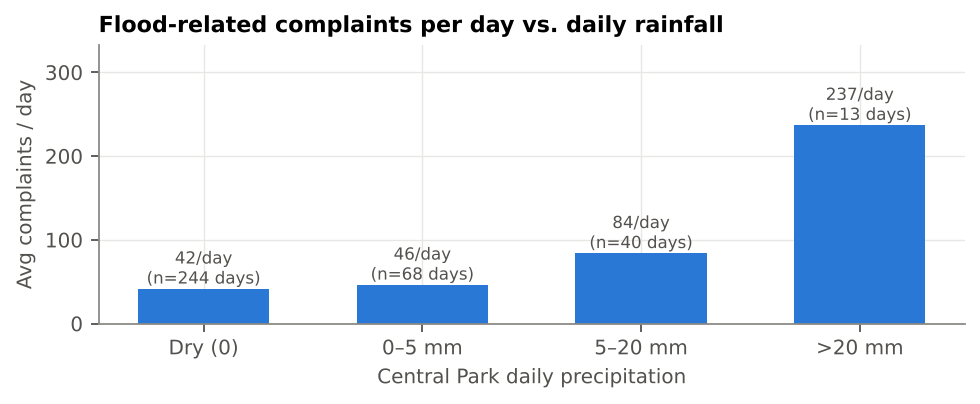

In [6]:
w = pd.read_csv('nyc_centralpark_2025.csv', parse_dates=['DATE']).rename(columns={'DATE': 'date', 'PRCP': 'rain_mm'})
daily = df.groupby('date').agg(flood=('flood', 'sum'), total=('unique_key', 'size')).reset_index()
daily = daily.merge(w[['date', 'rain_mm']], on='date', how='left').fillna({'rain_mm': 0})
daily['rain_bin'] = pd.cut(daily.rain_mm, [-0.1, 0, 5, 20, 1000], labels=['Dry (0)', '0–5 mm', '5–20 mm', '>20 mm'])
rb = daily.groupby('rain_bin', observed=True).flood.agg(['mean', 'size'])
print(rb)
STATS['flood_by_rain'] = rb['mean'].round(1).to_dict(); STATS['days_by_rain'] = rb['size'].to_dict()
STATS['corr_rain_flood'] = round(daily[['rain_mm', 'flood']].corr().iloc[0, 1], 2)
top_days = daily.sort_values('flood', ascending=False).head(5)[['date', 'flood', 'rain_mm']]
STATS['top_flood_days'] = [(d.strftime('%Y-%m-%d'), int(f), float(r)) for d, f, r in top_days.values]
print(top_days)
fig, ax = plt.subplots(figsize=(6.2, 2.6))
ax.bar(range(len(rb)), rb['mean'], color=BLUE, width=0.6)
for i, (m, n) in enumerate(zip(rb['mean'], rb['size'])):
    ax.text(i, m + 6, f'{m:.0f}/day\n(n={n} days)', ha='center', fontsize=7.5, color='#52514e')
ax.set_xticks(range(len(rb))); ax.set_xticklabels(rb.index.astype(str))
ax.set_ylim(0, rb['mean'].max() * 1.4)
ax.set_title('Flood-related complaints per day vs. daily rainfall'); ax.set_ylabel('Avg complaints / day'); ax.set_xlabel('Central Park daily precipitation')
fig.tight_layout(); fig.savefig('fig3_rain_flood.png'); plt.show()

## 5. Resolution time by hazard tier — is the queue already prioritised?

            count  50%    90%
tier                         
Critical  24381.0  0.5    5.6
High      67645.0  1.2   10.9
Routine   33115.0  5.9  123.0
{'Cave-in': 2.3, 'Sidewalk Collapsed': 3.4, 'Manhole Cover Missing': 0.1, 'Street Flooding': 0.6, 'Sewer Backup': 0.1, 'Pothole': 0.9, 'Broken Sidewalk': 10.9, 'Catch Basin Clogged/Flooding': 1.0}


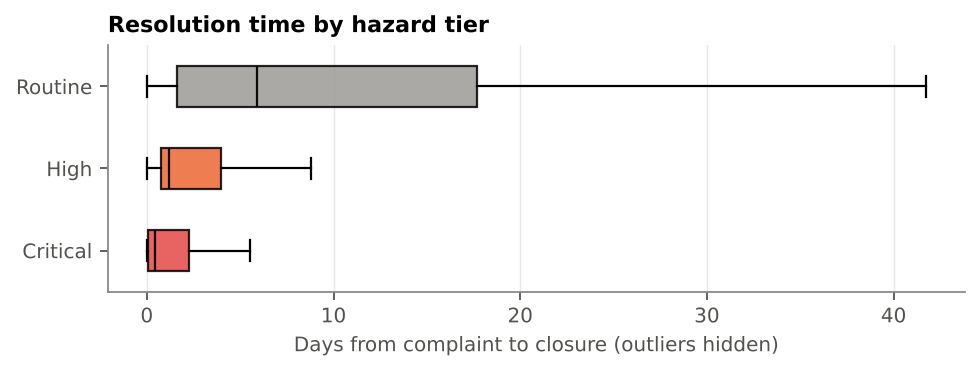

In [7]:
closed = df.dropna(subset=['res_days'])
res = closed.groupby('tier').res_days.describe(percentiles=[.5, .9])[['count', '50%', '90%']].round(1)
print(res); STATS['res_by_tier'] = res.to_dict(orient='index')
res_issue = closed.groupby('issue').res_days.median().round(1)
STATS['res_issue_sel'] = res_issue[['Cave-in', 'Sidewalk Collapsed', 'Manhole Cover Missing', 'Street Flooding', 'Sewer Backup', 'Pothole', 'Broken Sidewalk', 'Catch Basin Clogged/Flooding']].to_dict()
print(STATS['res_issue_sel'])
order = ['Critical', 'High', 'Routine']
fig, ax = plt.subplots(figsize=(6.2, 2.4))
data = [closed.loc[closed.tier == t, 'res_days'].clip(upper=120) for t in order]
bp = ax.boxplot(data, orientation='horizontal', tick_labels=order, showfliers=False, widths=0.5, patch_artist=True, medianprops=dict(color='#0b0b0b'))
for p, t in zip(bp['boxes'], order): p.set_facecolor(TIER_COL[t]); p.set_alpha(0.85)
ax.set_xlabel('Days from complaint to closure (outliers hidden)'); ax.set_title('Resolution time by hazard tier')
ax.grid(axis='y', visible=False)
fig.tight_layout(); fig.savefig('fig4_resolution.png'); plt.show()

## 6. Hotspots — do problems recur at the same spot?
Coordinates are snapped to a ~110 m grid (0.001°). A *recurrent* complaint is one followed by another
infrastructure complaint in the same cell within 30 days.

0.337


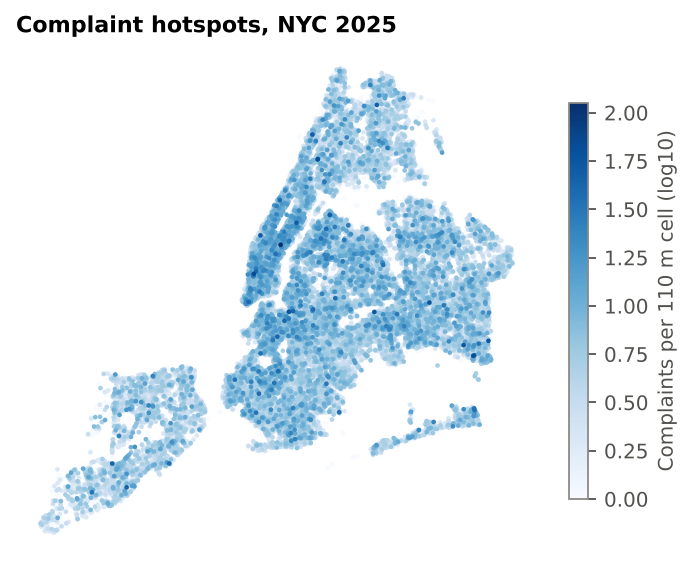

In [8]:
g = df.dropna(subset=['latitude']).copy()
g['cell'] = (g.latitude.round(3)).astype(str) + '_' + (g.longitude.round(3)).astype(str)
g = g.sort_values('created_date')
g['next_in_cell'] = g.groupby('cell').created_date.shift(-1)
g['gap_next'] = (g.next_in_cell - g.created_date).dt.total_seconds() / 86400
g['recur30'] = (g.gap_next <= 30).astype(int)
cell_n = g.groupby('cell').size()
STATS['n_cells'] = int(len(cell_n))
STATS['share_cells_ge5'] = round(float((cell_n >= 5).mean()), 3)
top10 = cell_n.sort_values(ascending=False)
STATS['share_complaints_top10pct_cells'] = round(float(top10.head(int(len(top10) * .1)).sum() / top10.sum()), 3)
print(STATS['share_complaints_top10pct_cells'])
fig, ax = plt.subplots(figsize=(4.4, 4.4))
cc = g.groupby('cell').agg(lat=('latitude', 'mean'), lon=('longitude', 'mean'), n=('unique_key', 'size'))
cc = cc.sort_values('n')
sc = ax.scatter(cc.lon, cc.lat, c=np.log10(cc.n), s=1.2, cmap='Blues', vmin=0, vmax=np.log10(cc.n.max()))
ax.set_aspect(1 / np.cos(np.radians(40.7))); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(sc, ax=ax, shrink=0.6, label='Complaints per 110 m cell (log10)')
ax.set_title('Complaint hotspots, NYC 2025')
fig.tight_layout(); fig.savefig('fig5_hotspots.png'); plt.show()

## 7. First experiment — predicting recurrent hotspots (proactive maintenance)
Target: will this location produce another infrastructure complaint within 30 days?
Only information available at complaint time is used. Chronological split: train Jan–Aug, test Sep–Nov
(December excluded because its 30-day future is not observed).

In [9]:
g = g.merge(w[['date', 'rain_mm']], on='date', how='left').fillna({'rain_mm': 0})
g = g.sort_values('created_date')
g['rain_3d'] = g.date.map(w.set_index('date').rain_mm.rolling(3, min_periods=1).sum()).fillna(0)
g['_one'] = 1
# complaints already seen in this cell in the previous 90 days (no future leakage)
g = g.set_index('created_date')
g['prior_90d'] = g.groupby('cell')['_one'].transform(lambda s: s.rolling('90D').count() - 1)
g = g.reset_index()
g['prior_any'] = g.groupby('cell').cumcount()
g = g[g.created_date < '2025-12-01']
cat = ['complaint_type', 'issue', 'tier', 'borough', 'location_type']
num = ['month', 'dow', 'rain_mm', 'rain_3d', 'prior_90d', 'prior_any']
g['location_type'] = g.location_type.fillna('Unknown')
train, test = g[g.created_date < '2025-09-01'], g[g.created_date >= '2025-09-01']
STATS['n_train'], STATS['n_test'] = len(train), len(test)
STATS['pos_rate_train'], STATS['pos_rate_test'] = round(train.recur30.mean(), 3), round(test.recur30.mean(), 3)
pre = ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore', min_frequency=20), cat)], remainder='passthrough')
models = {
    'Baseline (majority)': DummyClassifier(strategy='prior'),
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, class_weight='balanced', random_state=42),
    'Hist. Gradient Boosting': HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=42, class_weight='balanced'),
}
rows = []
for name, m in models.items():
    from sklearn.preprocessing import StandardScaler
    p = ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False), cat), ('n', StandardScaler(), num)])
    pipe = make_pipeline(p, m).fit(train[cat + num], train.recur30)
    pr = pipe.predict_proba(test[cat + num])[:, 1]
    rows.append({'Model': name, 'ROC-AUC': roc_auc_score(test.recur30, pr), 'PR-AUC': average_precision_score(test.recur30, pr),
                 'F1': f1_score(test.recur30, (pr >= 0.5).astype(int))})
    if name == 'Hist. Gradient Boosting': best_pipe, best_pr = pipe, pr
res_tbl = pd.DataFrame(rows).round(3); print(res_tbl)
STATS['model_results'] = res_tbl.to_dict(orient='records')
# top-decile precision: if crews inspect the 10% highest-risk spots, how many really recur?
thr = np.quantile(best_pr, 0.9)
STATS['precision_top10'] = round(float(test.recur30[best_pr >= thr].mean()), 3)
print('precision@top10%', STATS['precision_top10'])

                     Model  ROC-AUC  PR-AUC     F1
0      Baseline (majority)    0.500   0.399  0.000
1      Logistic Regression    0.670   0.586  0.540
2            Random Forest    0.673   0.584  0.571
3  Hist. Gradient Boosting    0.672   0.584  0.561
precision@top10% 0.716


In [10]:
json.dump(STATS, open('stats.json', 'w'), indent=1, default=str, ensure_ascii=False)